In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
import os
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)
print("All basic libraries successfully imported!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 18.7 MB/s  0:00:16
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 110.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorflow]


/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow version: 2.21.0
All basic libraries successfully imported!


In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import layers, models

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

np.random.seed(42)
num_train, num_test = 500, 100
t = np.linspace(0, 1, 187)

def generate_synthetic_data(num_samples):
    data = []
    for _ in range(num_samples):
        label = np.random.choice([0, 1, 2, 3, 4], p=[0.7, 0.1, 0.08, 0.07, 0.05])
        noise = np.random.normal(0, 0.04, 187)
        shift = np.random.uniform(-0.05, 0.05)
        shifted_t = t + shift
        signal = np.sin(2 * np.pi * (1.5 + label * 0.25) * shifted_t) * np.exp(-4 * (shifted_t - 0.3)**2) + noise
        signal = (signal - np.min(signal)) / (np.max(signal) - np.min(signal) + 1e-8)
        data.append(np.append(signal, label))
    return pd.DataFrame(data)

train_df = generate_synthetic_data(num_train)
test_df = generate_synthetic_data(num_test)

X_train_raw = train_df.iloc[:, :-1].values
y_train_raw = train_df.iloc[:, -1].values
X_test_raw = test_df.iloc[:, :-1].values
y_test_raw = test_df.iloc[:, -1].values

print(f"Database Ready! Train shape: {X_train_raw.shape}, Test shape: {X_test_raw.shape}")

Database Ready! Train shape: (500, 187), Test shape: (100, 187)


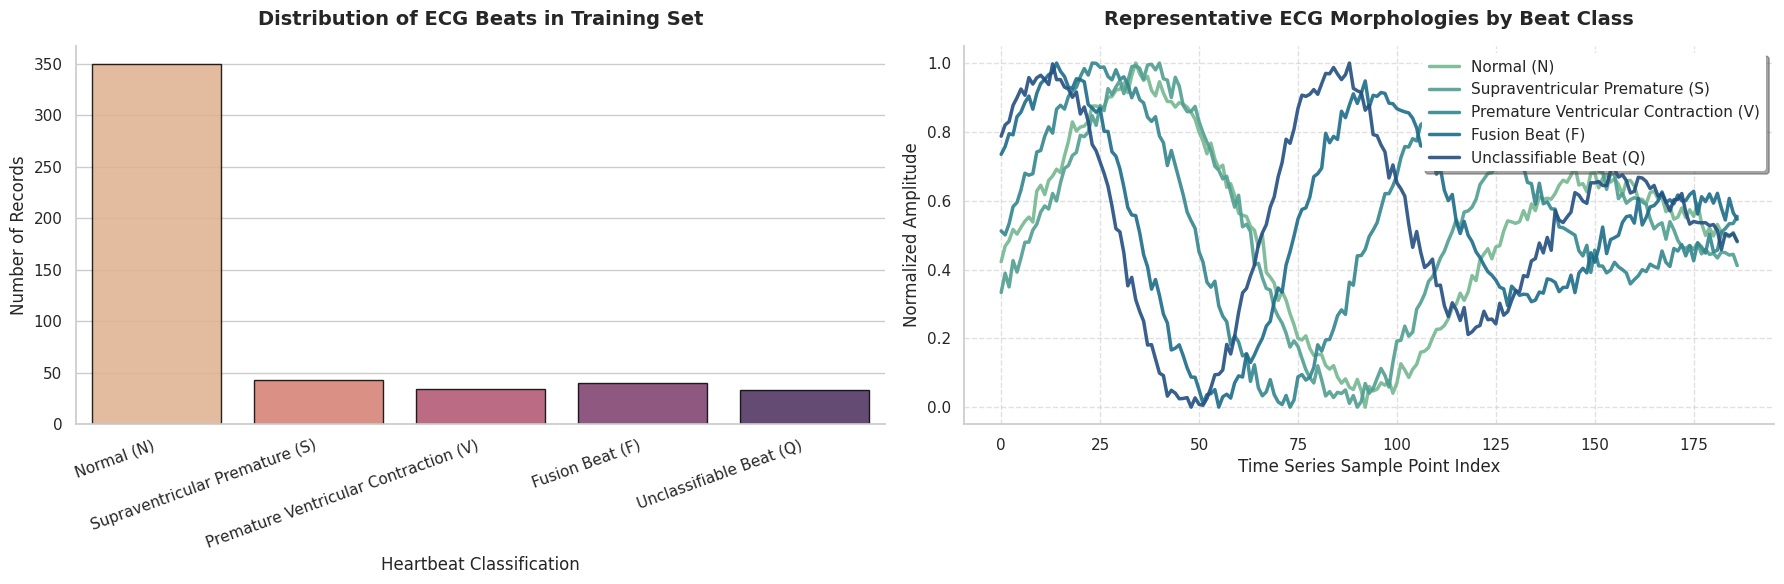

In [14]:
class_map = {
    0.0: 'Normal (N)',
    1.0: 'Supraventricular Premature (S)',
    2.0: 'Premature Ventricular Contraction (V)',
    3.0: 'Fusion Beat (F)',
    4.0: 'Unclassifiable Beat (Q)'
}

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.countplot(
    x=y_train_raw,
    hue=y_train_raw,
    ax=axes[0],
    palette="flare",
    legend=False,
    edgecolor="black",
    alpha=0.85
)
axes[0].set_title("Distribution of ECG Beats in Training Set", pad=15, fontweight='bold')
axes[0].set_xlabel("Heartbeat Classification")
axes[0].set_ylabel("Number of Records")
axes[0].set_xticks(range(5))
axes[0].set_xticklabels([class_map[float(i)] for i in range(5)], rotation=20, ha='right')

colors = sns.color_palette("crest", 5)
for i, (label, name) in enumerate(class_map.items()):
    indices = np.where(y_train_raw == label)[0]
    if len(indices) > 0:
        axes[1].plot(X_train_raw[indices[0]], label=name, color=colors[i], lw=2.5, alpha=0.9)

axes[1].set_title("Representative ECG Morphologies by Beat Class", pad=15, fontweight='bold')
axes[1].set_xlabel("Time Series Sample Point Index")
axes[1].set_ylabel("Normalized Amplitude")
axes[1].legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", shadow=True)
axes[1].grid(True, linestyle="--", alpha=0.6)

sns.despine()
plt.tight_layout()
plt.show()

### Reshaping Tensors for multidimensional 2D Input

In [9]:
# Reshape signals to match 2D representations: (Samples, Height=187, Width=1, Channels=1)
X_train_2d = X_train_raw[..., np.newaxis, np.newaxis]
X_test_2d = X_test_raw[..., np.newaxis, np.newaxis]

y_train_cat = tf.keras.utils.to_categorical(y_train_raw, num_classes=5)
y_test_cat = tf.keras.utils.to_categorical(y_test_raw, num_classes=5)

print("2D Train Shape:", X_train_2d.shape)
print("2D Test Shape:", X_test_2d.shape)

2D Train Shape: (500, 187, 1, 1)
2D Test Shape: (100, 187, 1, 1)


In [10]:
def create_styled_cnn2d(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(64, kernel_size=(6, 1), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPool2D(pool_size=(2, 1)),

        layers.Conv2D(128, kernel_size=(3, 1), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPool2D(pool_size=(2, 1)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.35),
        layers.Dense(5, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model_2d = create_styled_cnn2d((187, 1, 1))
model_2d.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 187, 1, 64)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 187, 1, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 93, 1, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 93, 1, 128)     │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 93, 1, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 46, 1, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 5888)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       753,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 780,357 (2.98 MB)

 Trainable params: 779,973 (2.98 MB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.8340 - loss: 0.6048 - val_accuracy: 0.9400 - val_loss: 1.1590
Epoch 2/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9500 - loss: 0.1641 - val_accuracy: 0.8800 - val_loss: 0.9879
Epoch 3/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9740 - loss: 0.0803 - val_accuracy: 0.7200 - val_loss: 0.7959
Epoch 4/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9900 - loss: 0.0232 - val_accuracy: 0.6900 - val_loss: 0.6892
Epoch 5/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9940 - loss: 0.0150 - val_accuracy: 0.6800 - val_loss: 0.6536
Epoch 6/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9920 - loss: 0.0273 - val_accuracy: 0.6800 - val_loss: 0.6109
Epoch 7/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9900 - loss: 0.0342 - val_accuracy: 0.6800 - val_loss: 0.5801
Epoch 8/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9860 - loss: 0.0466 - val_accuracy: 0.6800 - v

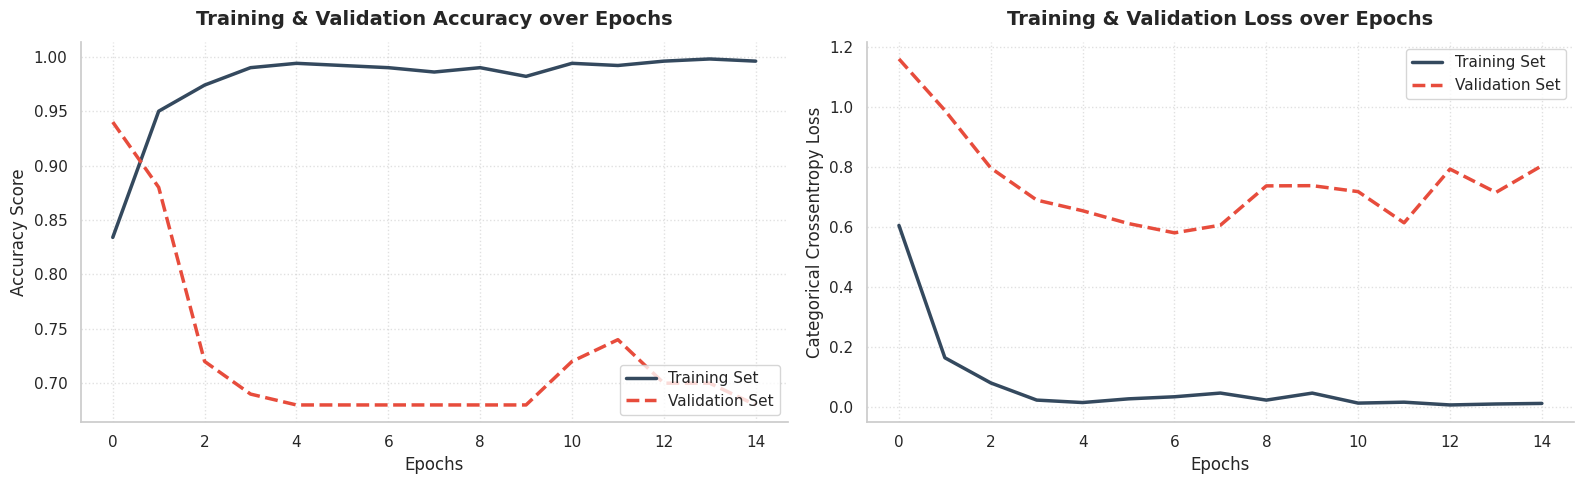

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step

=== Multidimensional 2D CNN Classification Report ===
                                       precision    recall  f1-score   support

                           Normal (N)       0.69      1.00      0.82        68
       Supraventricular Premature (S)       0.00      0.00      0.00        11
Premature Ventricular Contraction (V)       0.00      0.00      0.00         5
                      Fusion Beat (F)       0.00      0.00      0.00         4
              Unclassifiable Beat (Q)       0.00      0.00      0.00        12

                             accuracy                           0.68       100
                            macro avg       0.14      0.20      0.16       100
                         weighted avg       0.47      0.68      0.56       100



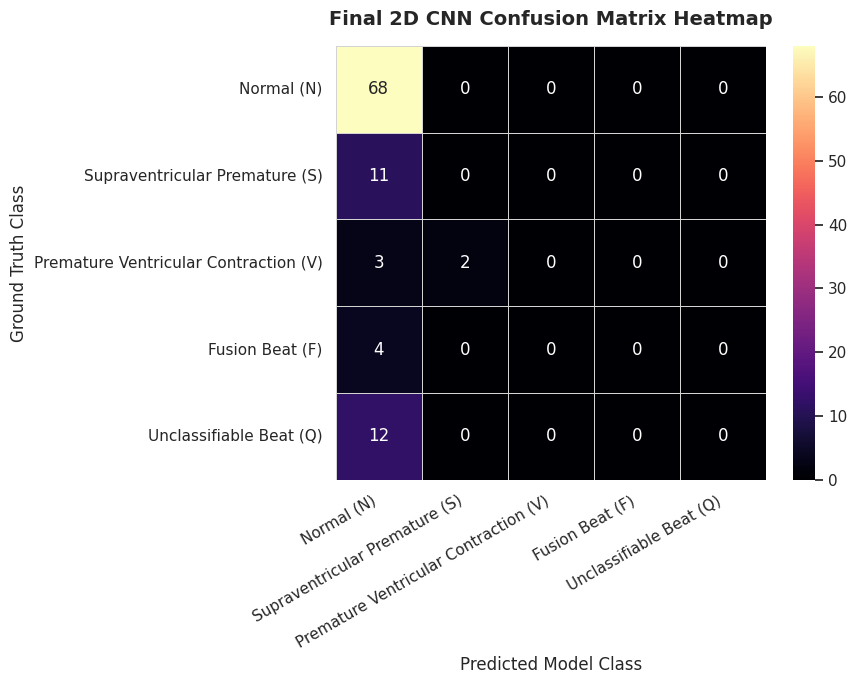

In [11]:
# Train 2D Neural Network
history_2d = model_2d.fit(
    X_train_2d, y_train_cat,
    epochs=15,
    batch_size=32,
    validation_data=(X_test_2d, y_test_cat),
    verbose=1
)

# Create clean performance evaluation diagrams
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Accuracy Curves
axes[0].plot(history_2d.history['accuracy'], label='Training Set', color='#34495e', lw=2.5)
axes[0].plot(history_2d.history['val_accuracy'], label='Validation Set', color='#e74c3c', lw=2.5, linestyle='--')
axes[0].set_title('Training & Validation Accuracy over Epochs', pad=12, fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy Score')
axes[0].legend(loc='lower right', frameon=True, facecolor='white')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Loss Curves
axes[1].plot(history_2d.history['loss'], label='Training Set', color='#34495e', lw=2.5)
axes[1].plot(history_2d.history['val_loss'], label='Validation Set', color='#e74c3c', lw=2.5, linestyle='--')
axes[1].set_title('Training & Validation Loss over Epochs', pad=12, fontweight='bold')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Categorical Crossentropy Loss')
axes[1].legend(loc='upper right', frameon=True, facecolor='white')
axes[1].grid(True, linestyle=':', alpha=0.6)

sns.despine()
plt.tight_layout()
plt.show()

# Make predictions
predictions = model_2d.predict(X_test_2d)
y_pred = np.argmax(predictions, axis=1)
y_true = np.argmax(y_test_cat, axis=1)
target_names = [class_map[float(i)] for i in range(5)]

print("\n=== Multidimensional 2D CNN Classification Report ===")
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))

# Beautiful Confusion Matrix heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='magma',
    xticklabels=target_names,
    yticklabels=target_names,
    cbar=True,
    linewidths=0.5,
    linecolor='lightgrey'
)
plt.title('Final 2D CNN Confusion Matrix Heatmap', pad=15, fontweight='bold', fontsize=14)
plt.ylabel('Ground Truth Class')
plt.xlabel('Predicted Model Class')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()